# ms06 去掉质心和水平转角之后的 PCA

S12 是在 14 个导出参数上做的主成分，那些参数不是点的正交坐标，两鱼距离占的方差会被放大。
这一次用同一套去除，但主成分做在去掉之后剩下的点坐标上：

1. 18 个数 = 两条鱼各 3 个点 × xyz。只用连续片段里的帧。
2. 减去 6 个点的质心，去掉整体位置（3 维）。
3. 绕 z 轴旋转，使「第一条鱼胸鳍 → 第二条鱼胸鳍」的水平方向落到 +x，去掉整体水平转角（1 维）。
4. 对这 18 个点坐标做 PCA。被去掉的 4 个方向特征值应接近 0，不进入后面的图。
5. 自相关、相关时间和代表量的规则与 ms05 相同：单位方差，1/e，相邻相关时间差 2 倍分组，|r| ≥ 0.5 才指定代表量。

只用开发组四个视频。K_1_3 和 P_1_3 不读。

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*keyword-only.*")
warnings.filterwarnings("ignore", message=".*keyword-only.*")


def find_repo_root(start: Path) -> Path:
    for d in [start, *start.parents]:
        if (d / "pyproject.toml").exists() and (d / "scripts" / "common" / "local_paths.py").exists():
            return d
    raise FileNotFoundError("no repository root above " + str(start))


REPO = find_repo_root(Path.cwd().resolve())
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from scripts.analysis import microstate as M

NOTEBOOK = "ms06_shape_pca.ipynb"
ROOT = M.roots()
OUT = ROOT["out"]
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})


def show(fig, stage, number, name):
    """Write S<stage>_<nn>_<name>.png into the output folder and display it."""
    path = M.save_fig(fig, stage, number, name, NOTEBOOK)
    display(Image(filename=str(path), width=900))
    print("figure:", path)


print("repository:", REPO)
print("figures  ->", OUT)

repository: C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline
figures  -> \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap


In [2]:
DEV = M.trials("dev")
print("dev:", DEV)
for experiment in M.trials("test"):
    try:
        M.load_trial(experiment)
    except PermissionError as err:
        print("held out:", err)
PARAMS = M.load_params()
VIDEOS = []
for experiment in DEV:
    proc = M.process_trial(experiment, PARAMS)
    item = {"experiment": experiment, "fps": proc["fps"], "seg": proc["seg"]}
    for pair in M.PAIR_NAMES:
        flat, valid = M.aligned_configuration(M.pair_points(proc["nodes"], pair))
        valid = valid & (proc["seg"] >= 0)
        flat[~valid] = np.nan
        item[pair] = {"flat": flat, "valid": valid, "scalars": M.pose_scalars(proc["nodes"], pair),
                      "n_valid": int(valid.sum())}
    VIDEOS.append(item)
    del proc
pd.DataFrame([{"experiment": v["experiment"], "pair": p, "n_valid": v[p]["n_valid"]} for v in VIDEOS for p in M.PAIR_NAMES])

dev: ['20251225_K_1_1_FCMC', '20260112_P_1_1_FCMC', '20260113_P_1_2_FCMC', '20251225_K_1_2_FCMC']
held out: 20251225_K_1_3_FCMC is in the test group; it is only read with final=True
held out: 20260112_P_1_3_FCMC is in the test group; it is only read with final=True


,experiment,pair,n_valid
0,20251225_K_1_1_FCMC,F-M1,333088
1,20251225_K_1_1_FCMC,F-M2,331217
2,20251225_K_1_1_FCMC,M1-M2,330523
3,20260112_P_1_1_FCMC,F-M1,321043
4,20260112_P_1_1_FCMC,F-M2,323367
5,20260112_P_1_1_FCMC,M1-M2,325746
6,20260113_P_1_2_FCMC,F-M1,326434
7,20260113_P_1_2_FCMC,F-M2,328492
8,20260113_P_1_2_FCMC,M1-M2,331394
9,20251225_K_1_2_FCMC,F-M1,324627


F-M1: kept 14 of 18; null eigenvalues [ 1.279e-12  7.403e-15 -9.318e-14 -6.914e-12]; 80% / 90% at component 2 / 2


F-M2: kept 14 of 18; null eigenvalues [ 1.034e-12  5.116e-14  1.985e-15 -1.331e-12]; 80% / 90% at component 2 / 2


M1-M2: kept 14 of 18; null eigenvalues [ 1.715e-12  8.901e-14  5.091e-15 -1.465e-12]; 80% / 90% at component 2 / 2


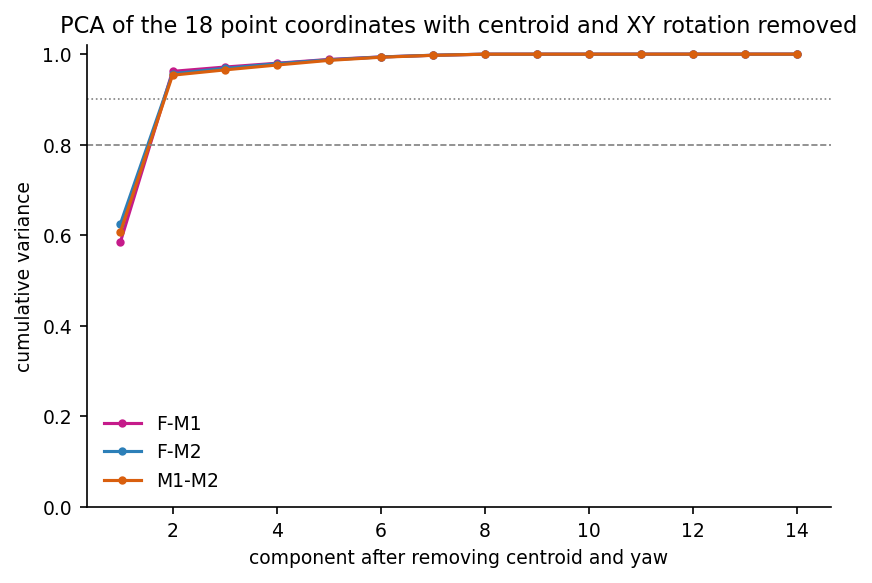

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S13_01_shape_pca_cumulative_variance.png


In [3]:
MODELS, SCORES, KEPT = {}, {}, {}
for pair in M.PAIR_NAMES:
    model = M.pca_fit(np.concatenate([v[pair]["flat"][v[pair]["valid"]] for v in VIDEOS]))
    keep = M.kept_components(model)
    MODELS[pair], KEPT[pair] = model, keep
    for v in VIDEOS:
        SCORES[(v["experiment"], pair)] = M.pca_scores(v[pair]["flat"], model)
    ev = model["eigenvalues"]
    cum = np.cumsum(ev[keep]) / ev[keep].sum()
    print(f"{pair}: kept {len(keep)} of {len(ev)}; null eigenvalues {np.array2string(ev[len(keep):], precision=3)}; "
          f"80% / 90% at component {int(np.searchsorted(cum, 0.8) + 1)} / {int(np.searchsorted(cum, 0.9) + 1)}")

fig, ax = plt.subplots(figsize=(6.4, 4))
for pair, color in zip(M.PAIR_NAMES, ("#c51b8a", "#2c7fb8", "#d95f0e")):
    ev = MODELS[pair]["eigenvalues"][KEPT[pair]]
    ax.plot(np.arange(1, len(ev) + 1), np.cumsum(ev) / ev.sum(), "-o", ms=3, color=color, label=pair)
ax.axhline(0.8, color="0.5", ls="--", lw=0.8)
ax.axhline(0.9, color="0.5", ls=":", lw=0.8)
ax.set_xlabel("component after removing centroid and yaw")
ax.set_ylabel("cumulative variance")
ax.set_ylim(0, 1.02)
ax.legend(frameon=False)
ax.set_title("PCA of the 18 point coordinates with centroid and XY rotation removed")
show(fig, 13, 1, "shape_pca_cumulative_variance")

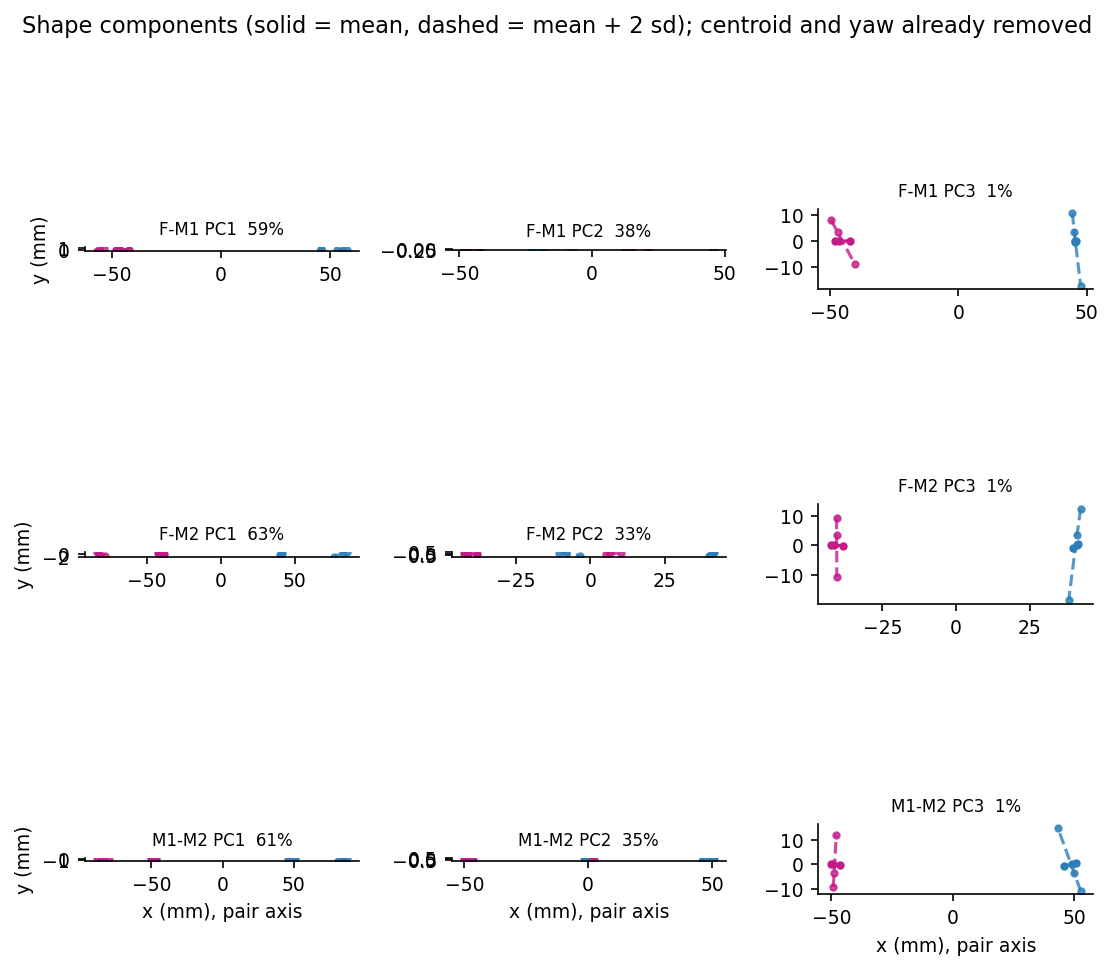

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S13_02_shape_pca_mode_shapes.png


In [4]:
def show_count(ev):
    cum = np.cumsum(ev) / ev.sum()
    return int(np.clip(np.searchsorted(cum, 0.80) + 1, 3, 5))


N_SHOW = max(show_count(MODELS[p]["eigenvalues"][KEPT[p]]) for p in M.PAIR_NAMES)
fig, axes = plt.subplots(len(M.PAIR_NAMES), N_SHOW, figsize=(2.5 * N_SHOW, 7.2))
for row, pair in enumerate(M.PAIR_NAMES):
    model, keep = MODELS[pair], KEPT[pair]
    mean = model["mean"].reshape(6, 3)
    a, b = pair.split("-")
    for col in range(N_SHOW):
        ax = axes[row, col]
        k = int(keep[col])
        moved_by = 2 * np.sqrt(model["eigenvalues"][k]) * model["eigenvectors"][:, k].reshape(6, 3)
        for idx, color in ((range(3), "#c51b8a"), (range(3, 6), "#2c7fb8")):
            base = mean[list(idx)]
            ax.plot(base[:, 0], base[:, 1], "-o", ms=3, color=color)
            ax.plot((base + moved_by[list(idx)])[:, 0], (base + moved_by[list(idx)])[:, 1], "--o", ms=3, color=color, alpha=0.8)
        share = model["eigenvalues"][k] / model["eigenvalues"][keep].sum()
        ax.set_aspect("equal")
        ax.set_title(f"{pair} PC{col + 1}  {100 * share:.0f}%", fontsize=8)
        if col == 0:
            ax.set_ylabel("y (mm)")
        if row == len(M.PAIR_NAMES) - 1:
            ax.set_xlabel("x (mm), pair axis")
fig.suptitle("Shape components (solid = mean, dashed = mean + 2 sd); centroid and yaw already removed")
fig.tight_layout()
show(fig, 13, 2, "shape_pca_mode_shapes")

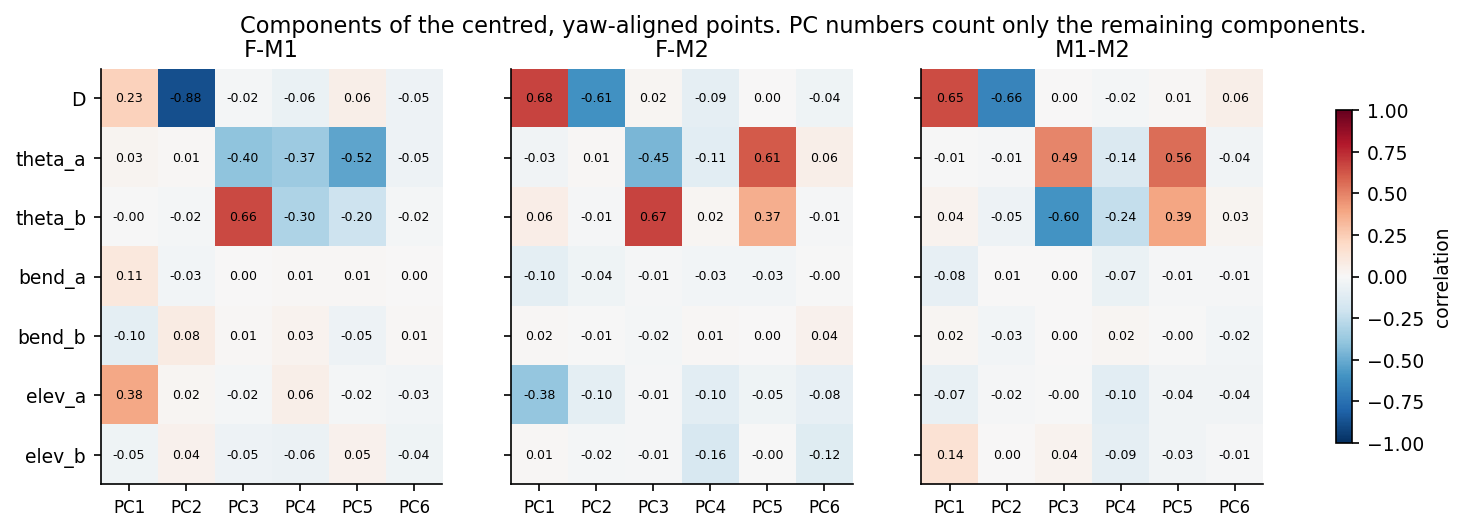

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S13_03_shape_pca_correlations.png


In [5]:
def cat(pair, column):
    blocks, segs, off = [], [], 0
    for v in VIDEOS:
        if column == "score":
            blocks.append(SCORES[(v["experiment"], pair)])
        else:
            blocks.append(v[pair]["scalars"][column])
        seg = v["seg"].copy()
        ok = seg >= 0
        seg[ok] = seg[ok] + off
        off = int(seg[ok].max()) + 1
        segs.append(seg)
    return np.concatenate(blocks), np.concatenate(segs)


CORR = {}
for pair in M.PAIR_NAMES:
    scores, seg = cat(pair, "score")
    scalars = {name: cat(pair, name)[0] for name in VIDEOS[0][pair]["scalars"]}
    table = M.correlate_modes(scores[:, KEPT[pair]], scalars, seg)
    table.insert(0, "pair", pair)
    CORR[pair] = table
corr = pd.concat(CORR.values(), ignore_index=True)
corr.to_csv(OUT / "S13_mode_correlations.csv", index=False)

variables = ["D", "theta_a", "theta_b", "bend_a", "bend_b", "elev_a", "elev_b"]
shown = 6
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True)
for ax, pair in zip(axes, M.PAIR_NAMES):
    keep = [int(i) + 1 for i in KEPT[pair][:shown]]
    table = CORR[pair].pivot(index="variable", columns="component", values="r").loc[variables, keep]
    im = ax.imshow(table.values, vmin=-1, vmax=1, cmap="RdBu_r", aspect="auto")
    ax.set_xticks(range(len(keep)))
    ax.set_xticklabels([f"PC{c}" for c in range(1, len(keep) + 1)], fontsize=8)
    ax.set_yticks(range(len(variables)))
    ax.set_yticklabels(variables)
    ax.set_title(pair)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f"{table.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=axes, shrink=0.8, label="correlation")
fig.suptitle("Components of the centred, yaw-aligned points. PC numbers count only the remaining components.")
show(fig, 13, 3, "shape_pca_correlations")

F-M1 [[22.25, 11.83], [2.19, 1.78, 1.78, 1.44, 1.17, 1.17, 0.77, 0.41, 0.33, 0.33, 0.17, 0.14]]


F-M2 [[14.6], [6.29], [2.19, 1.78, 1.78, 1.44, 1.17, 1.17, 0.77, 0.5, 0.33, 0.27, 0.17, 0.17]]


M1-M2 [[7.77, 4.13], [1.78, 1.78, 1.44, 0.95, 0.95, 0.95], [0.33, 0.27, 0.17, 0.14, 0.14, 0.14]]


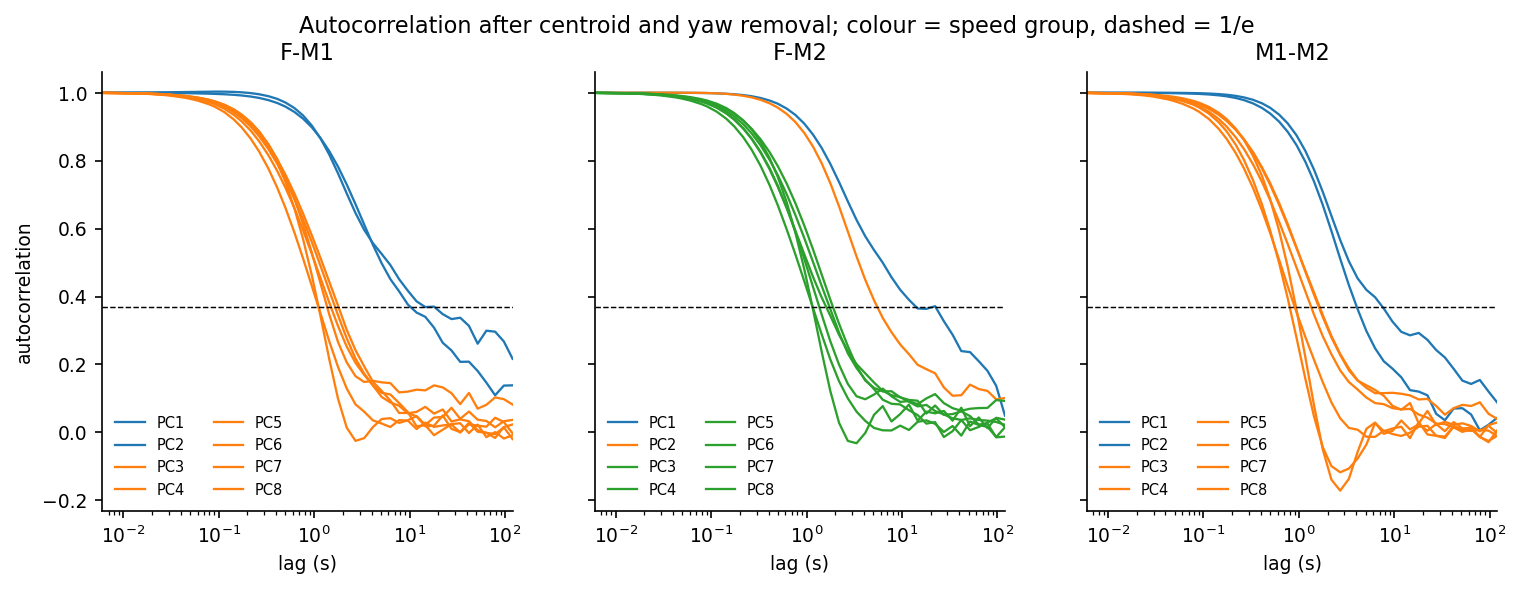

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S13_04_shape_pca_autocorrelation.png


In [6]:
LAGS = np.unique(np.round(np.geomspace(1, 166 * 120, 48)).astype(int))
TIME_ROWS, CURVES, GROUPS = [], {}, {}
for pair in M.PAIR_NAMES:
    n_pc = len(KEPT[pair])
    per_video = np.full((len(VIDEOS), n_pc), np.nan)
    pooled, psegs, off = [], [], 0
    for j, v in enumerate(VIDEOS):
        score = SCORES[(v["experiment"], pair)][:, KEPT[pair]]
        pooled.append(score)
        seg = v["seg"].copy()
        ok = seg >= 0
        seg[ok] = seg[ok] + off
        off = int(seg[ok].max()) + 1
        psegs.append(seg)
        for k in range(n_pc):
            tau, _ = M.correlation_time_s(score[:, k], v["seg"], v["fps"], LAGS)
            per_video[j, k] = tau
            TIME_ROWS.append({"pair": pair, "experiment": v["experiment"], "component": k + 1, "tau_s": tau, "scope": "video"})
    score, seg = np.concatenate(pooled), np.concatenate(psegs)
    curves = []
    for k in range(n_pc):
        tau, curve = M.correlation_time_s(score[:, k], seg, VIDEOS[0]["fps"], LAGS)
        curves.append(curve)
        TIME_ROWS.append({"pair": pair, "experiment": "pooled", "component": k + 1, "tau_s": tau, "scope": "pooled"})
    CURVES[pair] = np.vstack(curves)
    CURVES[(pair, "per_video")] = per_video
    tau = np.array([r["tau_s"] for r in TIME_ROWS if r["pair"] == pair and r["scope"] == "pooled"])
    GROUPS[pair] = M.speed_groups(tau, min_ratio=2.0)
    print(pair, [(np.round(tau[g], 2).tolist()) for g in GROUPS[pair]])

times = pd.DataFrame(TIME_ROWS)
times.to_csv(OUT / "S13_correlation_times.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, pair in zip(axes, M.PAIR_NAMES):
    group_of = {i: g for g, members in enumerate(GROUPS[pair]) for i in members}
    for k in range(min(8, len(CURVES[pair]))):
        ax.semilogx(LAGS / 166, CURVES[pair][k], color=plt.cm.tab10(group_of.get(k, 9)), lw=1.1, label=f"PC{k + 1}")
    ax.axhline(1 / np.e, color="k", ls="--", lw=0.7)
    ax.set_title(pair)
    ax.set_xlabel("lag (s)")
    ax.set_xlim(1 / 166, 120)
    ax.legend(frameon=False, fontsize=7, ncol=2)
axes[0].set_ylabel("autocorrelation")
fig.suptitle("Autocorrelation after centroid and yaw removal; colour = speed group, dashed = 1/e")
show(fig, 13, 4, "shape_pca_autocorrelation")

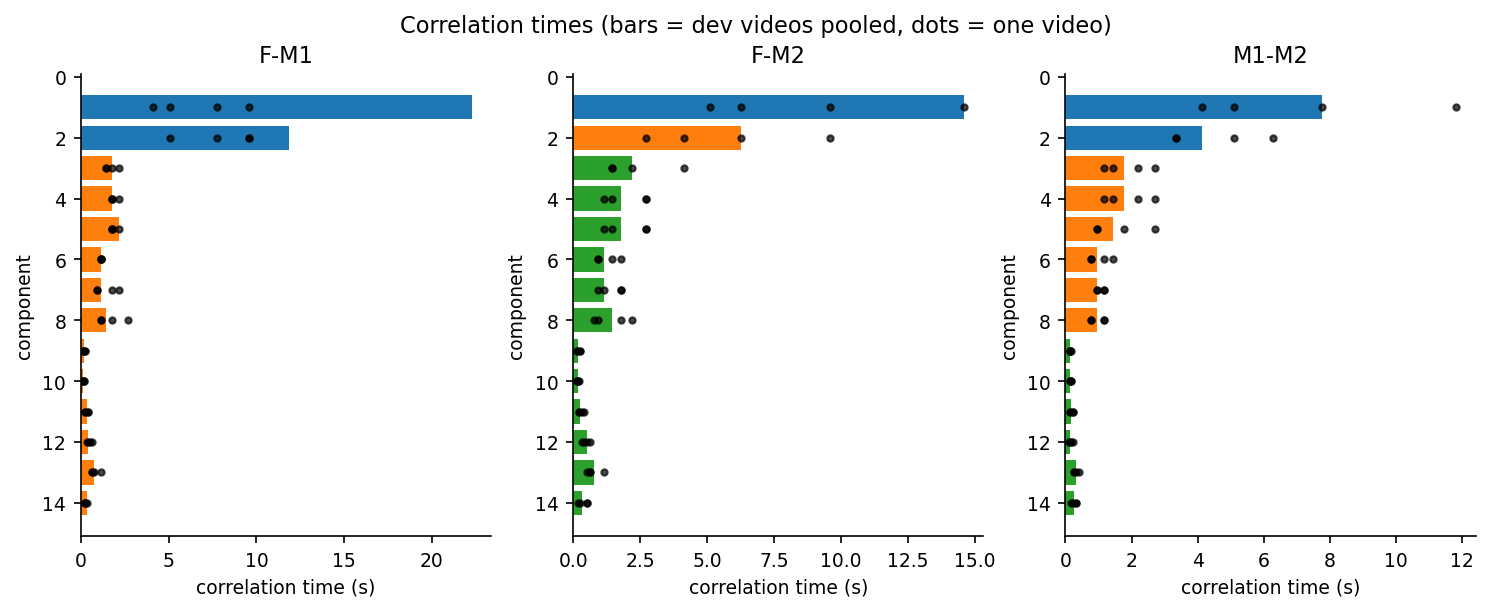

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S13_05_shape_pca_correlation_times.png


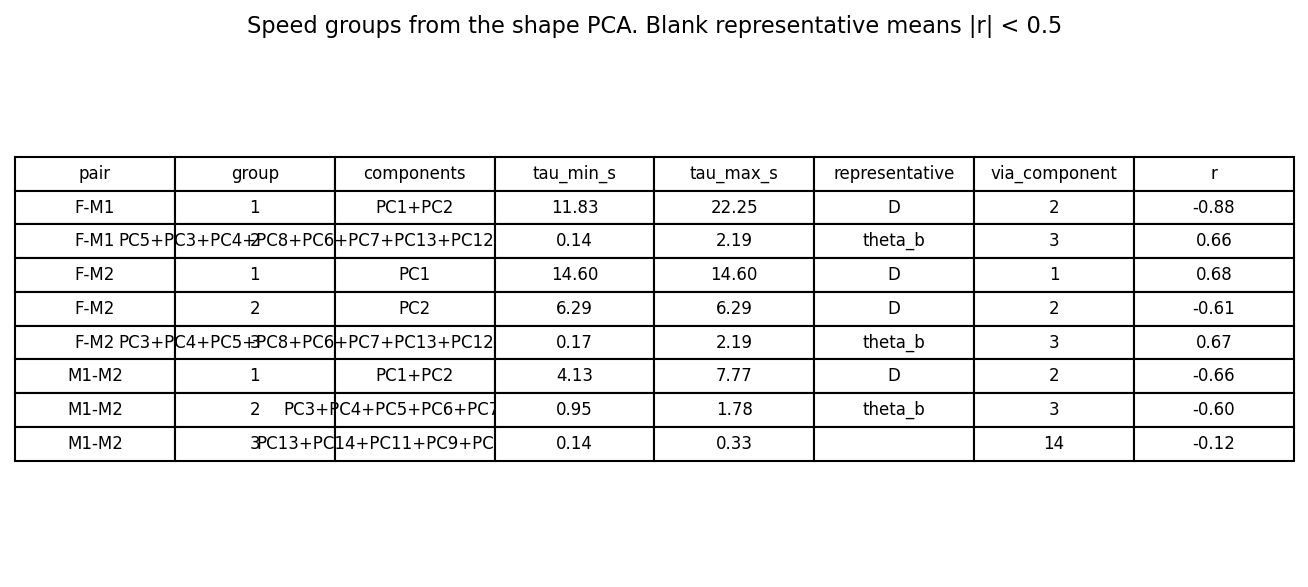

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S13_06_shape_pca_speed_groups.png


,pair,group,components,tau_min_s,tau_max_s,representative,via_component,r
0,F-M1,1,PC1+PC2,11.831325,22.253012,D,2,-0.878134
1,F-M1,2,PC5+PC3+PC4+PC8+PC6+PC7+PC13+PC12+PC14+PC11+PC...,0.144578,2.192771,theta_b,3,0.659982
2,F-M2,1,PC1,14.602410,14.602410,D,1,0.676540
3,F-M2,2,PC2,6.289157,6.289157,D,2,-0.605574
4,F-M2,3,PC3+PC4+PC5+PC8+PC6+PC7+PC13+PC12+PC14+PC11+PC...,0.174699,2.192771,theta_b,3,0.672870
5,M1-M2,1,PC1+PC2,4.126506,7.765060,D,2,-0.659251
6,M1-M2,2,PC3+PC4+PC5+PC6+PC7+PC8,0.945783,1.777108,theta_b,3,-0.601056
7,M1-M2,3,PC13+PC14+PC11+PC9+PC12+PC10,0.144578,0.331325,,14,-0.117942


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, pair in zip(axes, M.PAIR_NAMES):
    tau = times.query("pair == @pair and scope == 'pooled'").sort_values("component")["tau_s"].to_numpy()
    group_of = {i: g for g, members in enumerate(GROUPS[pair]) for i in members}
    ax.barh(np.arange(1, len(tau) + 1), tau, color=[plt.cm.tab10(group_of.get(i, 9)) for i in range(len(tau))])
    per = CURVES[(pair, "per_video")]
    for j in range(per.shape[0]):
        ax.plot(per[j], np.arange(1, len(tau) + 1), "o", ms=3, color="k", alpha=0.7)
    ax.set_xlabel("correlation time (s)")
    ax.set_ylabel("component")
    ax.set_title(pair)
    ax.invert_yaxis()
fig.suptitle("Correlation times (bars = dev videos pooled, dots = one video)")
show(fig, 13, 5, "shape_pca_correlation_times")

rows = []
for pair in M.PAIR_NAMES:
    tau = times.query("pair == @pair and scope == 'pooled'").sort_values("component")["tau_s"].to_numpy()
    for rank, members in enumerate(GROUPS[pair], start=1):
        pick = M.representative_of(members, CORR[pair])
        rows.append({"pair": pair, "group": rank, "components": "+".join(f"PC{i + 1}" for i in members),
                     "tau_min_s": float(np.min(tau[members])), "tau_max_s": float(np.max(tau[members])),
                     "representative": pick["variable"] or "", "via_component": pick["component"] or "",
                     "r": np.nan if pick["r"] is None else pick["r"]})
reps = pd.DataFrame(rows)
reps.to_csv(OUT / "S13_representatives.csv", index=False)
M.update_params("stage13", {"removed": "centroid (3) and yaw about z (1)", "on": "18 point coordinates",
                            "null_tolerance": 1e-6, "groups": reps.to_dict("records")})
show_df = reps.copy()
for col in ("tau_min_s", "tau_max_s", "r"):
    show_df[col] = show_df[col].map(lambda v: "" if pd.isna(v) else f"{v:.2f}")
fig, ax = plt.subplots(figsize=(11, 0.42 * len(show_df) + 1.2))
ax.axis("off")
table = ax.table(cellText=show_df.values, colLabels=list(show_df.columns), loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.35)
ax.set_title("Speed groups from the shape PCA. Blank representative means |r| < 0.5")
show(fig, 13, 6, "shape_pca_speed_groups")
reps